# Analiza strefy wpływu kopalni Turów
Celem analizy jest zbadanie zależności między średnią prędkością osiadania (`mean_velocity`) a odległością od centrum odkrywki KWB Turów. Wyniki zostaną zwizualizowane na wykresie oraz wyeksportowane do formatu GeoPackage dla QGIS.

## 1. Import bibliotek i wczytanie wyników

In [2]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point
import numpy as np

sns.set_theme(style="whitegrid")


In [3]:
# Wczytanie gotowych wyników z głównego pipeline'u
df = pd.read_csv('EGMS_Turow_U_results.csv')

# Konwersja do GeoDataFrame (EPSG:3035)
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df['easting'], df['northing']),
    crs="EPSG:3035"
)

print(f"Wczytano {len(gdf)} punktów PS.")

Wczytano 6268 punktów PS.


## 2. Zdefiniowanie lokalizacji kopalni i obliczenie odległości

Aby sprawdzić wpływ kopalni, wyznaczymy przybliżony punkt środkowy odkrywki i obliczymy odległość każdego punktu PS od tego miejsca.

In [6]:
# Wczytanie warstw wektorowych z pliku SHP
kopalnia_shp = gpd.read_file('mask/maska_kopalnia_zwalowisko.shp').to_crs("EPSG:3035")

# Rozdzielenie obiektów (przykład: jeśli różnią się np. kolumną 'typ')
mine_polygon = kopalnia_shp[kopalnia_shp['FID'] == 1].geometry.iloc[0]
zwalowisko_polygon = kopalnia_shp[kopalnia_shp['FID'] == 2].geometry.union_all()

# Odfiltrowanie punktów leżących na zwałowisku (~ oznacza odwrócenie warunku)
gdf = gdf[~gdf.geometry.intersects(zwalowisko_polygon)]

# Obliczenie odległości od krawędzi odkrywki tylko dla przefiltrowanych punktów
gdf['distance_to_mine_km'] = gdf.geometry.distance(mine_polygon) / 1000.0

## 3. Wizualizacja: Zależność osiadania od odległości

Poniższy wykres punktowy przedstawia zależność prędkości osiadania od odległości od kopalni. Dodana czerwona linia pokazuje uśrednioną prędkość w przedziałach co 1 km, co pozwala łatwo dostrzec trend tłumienia osiadań wraz ze wzrostem odległości.

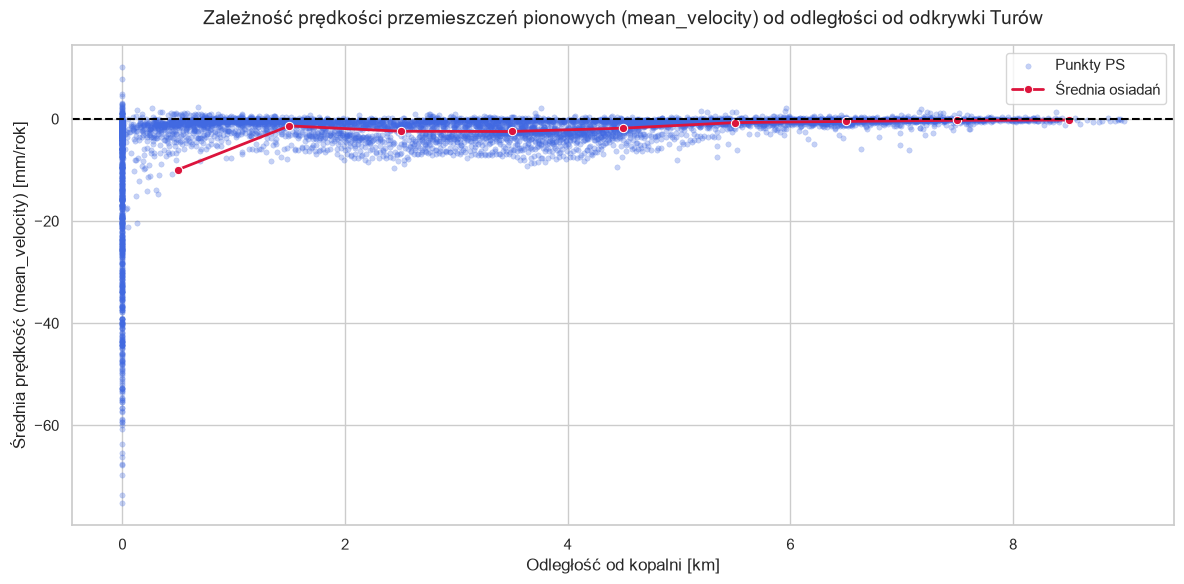

In [7]:
plt.figure(figsize=(12, 6))

# Wykres rozrzutu (Scatter plot)
sns.scatterplot(
    data=gdf, 
    x='distance_to_mine_km', 
    y='mean_velocity', 
    alpha=0.3, 
    s=15, 
    color='royalblue', 
    edgecolor=None,
    label='Punkty PS'
)

# Pogrupowanie odległości w przedziały 1 km, by narysować uśredniony trend
gdf['dist_bin'] = np.floor(gdf['distance_to_mine_km'])
bin_means = gdf.groupby('dist_bin')['mean_velocity'].mean().reset_index()
bin_means['dist_bin'] = bin_means['dist_bin'] + 0.5  # przesunięcie na środek przedziału

sns.lineplot(
    data=bin_means, 
    x='dist_bin', 
    y='mean_velocity', 
    color='crimson', 
    linewidth=2, 
    marker='o', 
    label='Średnia osiadań'
)

# Linia zerowa (brak ruchu)
plt.axhline(0, color='black', linewidth=1.5, linestyle='--')

# Opisy wykresu
plt.title('Zależność prędkości przemieszczeń pionowych (mean_velocity) od odległości od odkrywki Turów', fontsize=14, pad=15)
plt.xlabel('Odległość od kopalni [km]', fontsize=12)
plt.ylabel('Średnia prędkość (mean_velocity) [mm/rok]', fontsize=12)
plt.legend()
plt.tight_layout()

plt.show()

## 4. Eksport danych pod oprogramowanie QGIS

Eksportujemy naszą warstwę z obliczonymi odległościami do formatu GeoPackage. 
Dodatkowo wygenerujemy poligonowe **strefy buforowe** (co 2 km) od środka kopalni, które będzie można nałożyć w QGIS jako okręgi pokazujące strefy wpływu.

In [8]:
output_gpkg = 'EGMS_strefa_wplywu.gpkg'

# 1. Eksport punktów (usuwamy kolumnę techniczną dist_bin)
gdf.drop(columns=['dist_bin'], errors='ignore').to_file(
    output_gpkg, 
    layer='punkty_ps_odleglosci', 
    driver='GPKG'
)

# 2. Utworzenie buforów (strefy co 2 km do 10 km) i ich eksport
buffers = []
for dist in range(2, 12, 2):
    buf_geom = mine_polygon.buffer(dist * 1000)  # buffer potrzebuje metrów
    buffers.append({'promien_km': dist, 'geometry': buf_geom})

buffers_gdf = gpd.GeoDataFrame(buffers, crs="EPSG:3035")
buffers_gdf.to_file(output_gpkg, layer='strefy_buforowe', driver='GPKG')

print(f"Gotowe! Wyeksportowano warstwy GIS do pliku: {output_gpkg}")
print("Plik możesz przeciągnąć bezpośrednio do okna QGIS.")

Gotowe! Wyeksportowano warstwy GIS do pliku: EGMS_strefa_wplywu.gpkg
Plik możesz przeciągnąć bezpośrednio do okna QGIS.
